# Homework 4 — Who dies in a crash? Belo Horizonte, 2016–2024

**Márton Csepregi** · Data Science workshop, lesson 4 (classification)

A crash is reported with everyone involved. For each person: **will they die?** This notebook follows the lesson's
path (raw data → EDA → cleaning → encoding → split → CV → evaluation → model ladder → feedback loop → tuning → test once)
and writes every chart into `assets/` for the slides (`slides.html`). The class presentation without code is
`homework.md`.

**Results in short:** tuned XGBoost on 2023–2024: PR-AUC **0.137** [0.101; 0.174] vs **0.051** for logistic
regression; the riskiest 5% of people hold **67%** of the deaths. Three leaks had to go first (with them, CV PR-AUC
was 0.877).

In [1]:
import json
import re
import time
from pathlib import Path
from urllib.request import urlopen, urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, accuracy_score)
from sklearn.model_selection import KFold, ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEED = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Chart style = the slides' burgundy theme (the colour overrides in slides.html), so the PNGs in assets/ drop straight
# into the slides. BLUE is the neutral series, ORANGE the highlight, GOLD the table headers (names kept from the lesson).
SURFACE, INK, INK2, GRID = "#24161b", "#f3ebe4", "#c9b8b0", "#4a3238"
BLUE, ORANGE, GOLD = "#8fb3d9", "#e0607e", "#e0b450"
RAISED, HL_ROW, HL_CELL = "#331f26", "#3d2a30", "#7a2d3e"
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list("burgundy", [INK, ORANGE, HL_CELL])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.alpha": .7,
    "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15, "legend.fontsize": 13, "figure.dpi": 80})
ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)
pct = plt.FuncFormatter(lambda v, _: f"{v:.1%}")


def keep(fig, name):
    # save for the slides, then show in the notebook
    fig.savefig(ASSETS / f"{name}.png", dpi=170, bbox_inches="tight", facecolor=SURFACE)
    plt.show()


def table_png(df, name, hl_rows=(), hl_cells=(), fs=16):
    # dark table image (the deck engine has no table block) — adapted from the lesson's build_assets.py
    widths = [max(len(str(v)) for v in [c, *df[c]]) * 0.155 + 0.8 for c in df.columns]
    fig, ax = plt.subplots(figsize=(sum(widths), .62 * (len(df) + 1)))
    ax.axis("off")
    t = ax.table(cellText=df.values.tolist(), colLabels=list(df.columns), loc="center", cellLoc="center",
                 colWidths=[w / sum(widths) for w in widths])
    t.auto_set_font_size(False)
    t.set_fontsize(fs)
    t.scale(1, 1.9)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor(GRID)
        if r == 0:
            cell.set_facecolor(RAISED); cell.get_text().set_color(GOLD); cell.get_text().set_fontweight("bold")
        else:
            cell.set_facecolor(HL_ROW if (r - 1) in hl_rows else SURFACE)
            cell.get_text().set_color(INK)
            if (r - 1, c) in hl_cells:
                cell.set_facecolor(HL_CELL); cell.get_text().set_fontweight("bold")
    keep(fig, name)

## 0. The data

Kaggle's ["Car Accident 2020"](https://www.kaggle.com/datasets/raphaelmarconato/detran-accidents-2020) claims to be
*all car accidents in Brazil in 2020*. It is the 2020 **people** file of **Belo Horizonte**'s open data (one row = one
person). The next cell downloads the original 2016–2024 tables (accidents, people, vehicles; ODbL, no login) from the
city's CKAN portal into `data/` if they are missing.

In [2]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)
YEARS = range(2016, 2025)
API = "https://dados.pbh.gov.br/api/3/action/package_show?id="
PACKAGES = {"si-bol-": "relacao-de-ocorrencias-de-acidentes-de-transito-com-vitima",           # one row per accident
            "si_env-": "relacao-das-pessoas-envolvidas-nos-acidentes-de-transito-com-vitima",  # one row per person
            "si-veic-": "relacao-dos-veiculos-envolvidos-nos-acidentes-de-transito-com-vitima"}  # one row per vehicle
RENAME = {"Nº_boletim": "num_boletim", "NUMERO_BOLETIM": "num_boletim", "DATA HORA_BOLETIM": "data_hora_boletim"}


def download_missing():
    for prefix, pkg in PACKAGES.items():
        needed = [DATA / f"{prefix}{y}.csv" for y in YEARS if not (DATA / f"{prefix}{y}.csv").exists()]
        if not needed:
            continue
        urls = {r["url"].rsplit("/", 1)[-1]: r["url"] for r in json.load(urlopen(API + pkg))["result"]["resources"]}
        for f in needed:
            print("downloading", f.name)
            urlretrieve(urls[f.name], f)


def read(prefix):
    frames = []
    for y in YEARS:
        f = pd.read_csv(DATA / f"{prefix}{y}.csv", sep=";", encoding="latin-1", dtype=str)
        f.columns = [c.strip() for c in f.columns]
        # the id column is spelled differently across years ("Nº_boletim", "NUMERO_BOLETIM", and "N§_boletim" in the
        # 2023 vehicle file, an encoding slip in the source): without this, 2023 vehicles silently fail to join
        f.columns = ["num_boletim" if re.fullmatch(r"n\S{0,5}_boletim", c.lower()) else c for c in f.columns]
        f = f.rename(columns=RENAME).apply(lambda s: s.str.strip())
        assert "num_boletim" in f.columns, (prefix, y)
        f["year"] = y
        frames.append(f)
    return pd.concat(frames, ignore_index=True)


download_missing()
bol, env, veic = read("si-bol-"), read("si_env-"), read("si-veic-")
print(f"accidents: {len(bol):,} | people involved: {len(env):,} | vehicles: {len(veic):,}")
print("2020 people file rows:", (env["year"] == 2020).sum(), "(the Kaggle 'Car Accident 2020' dataset is this file)")

accidents: 110,764 | people involved: 240,257 | vehicles: 202,545
2020 people file rows: 22643 (the Kaggle 'Car Accident 2020' dataset is this file)


## 1. The question and the target

**Positive class: the person dies** (`cod_severidade == 2`). Use case: a trauma team or emergency coordinator deciding
who needs urgent care. A missed death is far worse than a false alarm, so recall matters more than precision.
People whose outcome was not recorded (3.9%) are dropped: there is no label. `declaracao_obito` (the death certificate,
which Kaggle's description calls the target) is empty.

In [3]:
print(env["desc_severidade"].value_counts().to_string())
print("\ndeath-certificate column (declaracao_obito) — share of non-zero values:", (env["declaracao_obito"] != "0").mean())

desc_severidade
NAO FATAL         131474
SEM FERIMENTOS     98392
NAO INFORMADO       9279
FATAL               1112

death-certificate column (declaracao_obito) — share of non-zero values: 8.324419267700838e-06


In [4]:
# --- people: target and person-level features --------------------------------------------------------
P = env[env["cod_severidade"].isin(["1", "2", "3"])].copy()        # "0" = severity not recorded: no label
P["y"] = (P["cod_severidade"] == "2").astype(int)

P["role"] = np.select([P["pedestre"] == "S", P["condutor"] == "S", P["passageiro"] == "S"],
                      ["pedestrian", "driver", "passenger"], "unknown")
VEH = {"AUTOMOVEL": "car", "MOTOCICLETA": "motorcycle", "MOTONETA": "motorcycle", "CICLOMOTOR": "motorcycle",
       "ONIBUS": "bus", "MICROONIBUS": "bus", "CAMINHAO": "truck", "CAMINHAO-TRATOR": "truck",
       "REBOQUE E SEMI-REBOQUE": "truck", "CAMINHONETE": "pickup/van", "CAMIONETA": "pickup/van", "KOMBI": "pickup/van",
       "BICICLETA": "bicycle", "": "none"}
P["vehicle"] = P["especie_veiculo"].map(VEH).fillna("other")
P["age"] = pd.to_numeric(P["Idade"], errors="coerce")
P.loc[(P["age"] == 0) & (P["nascimento"] == "00/00/0000"), "age"] = np.nan   # 0 with no birth date = unknown
P.loc[P["age"] > 100, "age"] = np.nan
P["sex"] = P["sexo"].replace({"0": "not recorded"})
P["seatbelt"] = P["cinto_seguranca"]
P["drunk"] = P["Embreagues"]
P["licence"] = P["categoria_habilitacao"].replace({"": "blank"})

# --- accident-level features ---------------------------------------------------------------------------
when = pd.to_datetime(bol["data_hora_boletim"], format="%d/%m/%Y %H:%M")
# location: UTM coordinates (metres) -> 1 km grid cell; hundreds of values, like 'Model' in the lesson
cx = pd.to_numeric(bol["COORDENADA_X"], errors="coerce")
cy = pd.to_numeric(bol["COORDENADA_Y"], errors="coerce")
ok = cx.between(5.8e5, 6.3e5) & cy.between(7.77e6, 7.83e6)       # inside the Belo Horizonte area
B = pd.concat([bol, pd.DataFrame({
    "when": when, "hour": when.dt.hour, "weekday": when.dt.day_of_week, "month": when.dt.month,
    "speed_limit": pd.to_numeric(bol["VELOCIDADE_PERMITIDA"], errors="coerce").replace(0, np.nan),
    "accident_type_raw": bol["DESC_TIPO_ACIDENTE"],
    # the type NAME contains the outcome ("... COM VITIMA FATAL" / "... SEM VITIMA FATAL"): merge those two
    "accident_type": bol["DESC_TIPO_ACIDENTE"].str.replace(r" (COM|SEM) VITIMA FATAL$", "", regex=True),
    "weather": bol["DESC_TEMPO"], "pavement": bol["PAVIMENTO"], "region": bol["DESC_REGIONAL"].replace({"": "unknown"}),
    "n_people": bol["num_boletim"].map(env.groupby("num_boletim").size()),
    "n_vehicles": bol["num_boletim"].map(veic.groupby("num_boletim").size()),
    "grid_cell": np.where(ok, (cx // 1000).astype("Int64").astype(str) + "_" + (cy // 1000).astype("Int64").astype(str), "unknown"),
})], axis=1)
ACC = ["num_boletim", "when", "hour", "weekday", "month", "speed_limit", "accident_type", "accident_type_raw",
       "weather", "pavement", "region", "grid_cell", "n_people", "n_vehicles", "INDICADOR_FATALIDADE"]
df = P.merge(B[ACC], on="num_boletim", how="left", validate="many_to_one")
assert df["when"].notna().all()
print(f"people with a recorded outcome: {len(df):,} | deaths: {df['y'].sum():,} | rate: {df['y'].mean():.4%}")
df.groupby("year").agg(people=("y", "size"), deaths=("y", "sum"), death_rate=("y", "mean")).round(4)

people with a recorded outcome: 230,978 | deaths: 1,112 | rate: 0.4814%


,people,deaths,death_rate
year,,,
2016,25764,135,0.0052
2017,25222,121,0.0048
2018,24193,113,0.0047
2019,27779,105,0.0038
2020,21995,113,0.0051
2021,23290,113,0.0049
2022,25306,131,0.0052
2023,29514,122,0.0041
2024,27915,159,0.0057


## 2. EDA

Base rate: **0.48%** deaths. Four views: who (role × vehicle), when and how old, the seatbelt (a Simpson's paradox:
2.8× overall, 1.6× among car occupants), and a column whose meaning changed in 2022 (motorcyclists were "97% belted"
until 2021, i.e. the helmet; 2% from 2022).

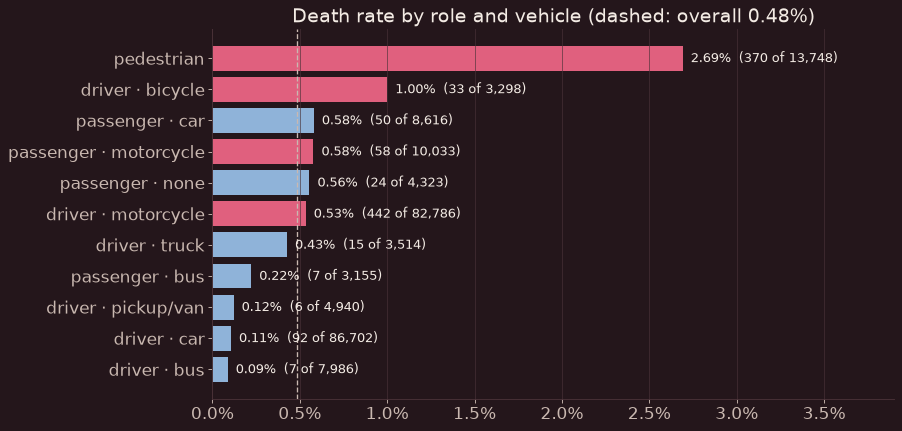

In [5]:
base = df["y"].mean()
grp = (df[df["role"] != "unknown"]
       .assign(who=lambda d: np.where(d["role"] == "pedestrian", "pedestrian", d["role"] + " · " + d["vehicle"]))
       .groupby("who")["y"].agg(["size", "mean", "sum"]))
grp = grp[grp["size"] >= 2000].sort_values("mean")
fig, ax = plt.subplots(figsize=(11, 6))
colors = [ORANGE if w == "pedestrian" or "motorcycle" in w or "bicycle" in w else BLUE for w in grp.index]
ax.barh(grp.index, grp["mean"], color=colors)
for i, (m, n, s) in enumerate(zip(grp["mean"], grp["size"], grp["sum"])):
    ax.text(m, i, f"  {m:.2%}  ({s} of {n:,})", va="center", fontsize=12, color=INK)
ax.axvline(base, color=INK2, ls="--", lw=1.2)
ax.set_xlim(0, grp["mean"].max() * 1.45)
ax.xaxis.set_major_formatter(pct)
ax.set(title=f"Death rate by role and vehicle (dashed: overall {base:.2%})")
ax.grid(axis="y", visible=False)
keep(fig, "eda_who")

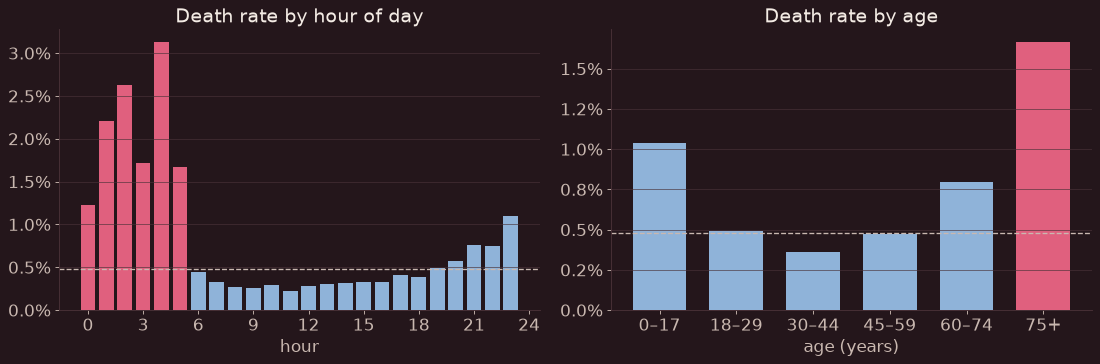

00–05h: 1.93% vs rest of the day: 0.40% (4.9×)
by age band: {'0–17': 0.0104, '18–29': 0.0049, '30–44': 0.0036, '45–59': 0.0047, '60–74': 0.0079, '75+': 0.0166}


In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
h = df.groupby("hour")["y"].agg(["size", "mean"])
a1.bar(h.index, h["mean"], color=[ORANGE if x <= 5 else BLUE for x in h.index], width=.8)
a1.axhline(base, color=INK2, ls="--", lw=1.2)
a1.xaxis.set_major_locator(plt.MultipleLocator(3))
a1.yaxis.set_major_formatter(pct)
a1.set(title="Death rate by hour of day", xlabel="hour")
a1.grid(axis="x", visible=False)
bands = pd.cut(df["age"], [0, 17, 29, 44, 59, 74, 100], labels=["0–17", "18–29", "30–44", "45–59", "60–74", "75+"])
a = df.groupby(bands, observed=True)["y"].mean()
a2.bar(a.index.astype(str), a.values, color=[ORANGE if x == "75+" else BLUE for x in a.index.astype(str)], width=.7)
a2.axhline(base, color=INK2, ls="--", lw=1.2)
a2.yaxis.set_major_formatter(pct)
a2.set(title="Death rate by age", xlabel="age (years)")
a2.grid(axis="x", visible=False)
plt.tight_layout()
keep(fig, "eda_hour_age")
night, day = df.loc[df["hour"] <= 5, "y"].mean(), df.loc[df["hour"] > 5, "y"].mean()
print(f"00–05h: {night:.2%} vs rest of the day: {day:.2%} ({night / day:.1f}×)")
print("by age band:", a.round(4).to_dict())

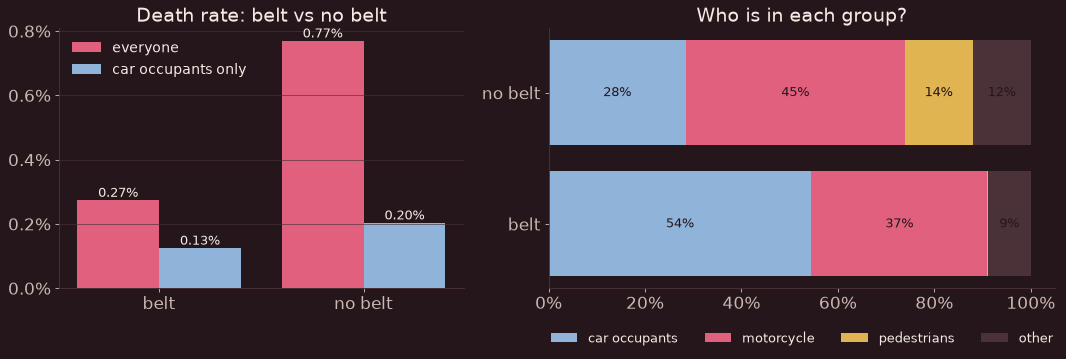

overall no-belt / belt: 2.81 | car occupants: 1.62
seatbelt values recorded for motorcyclists: {'SIM': 49079, 'NÃO': 43708, 'NÃO INFORMADO': 73}


In [7]:
# Simpson's paradox candidate: "no seatbelt" mixes in motorcyclists and pedestrians
sb = df[df["seatbelt"].isin(["SIM", "NÃO"])].copy()
sb["belt"] = sb["seatbelt"].map({"SIM": "belt", "NÃO": "no belt"})
car_occ = sb["vehicle"].isin(["car", "pickup/van"]) & sb["role"].isin(["driver", "passenger"])
overall = sb.groupby("belt")["y"].mean()
inside = sb[car_occ].groupby("belt")["y"].mean()
mix = sb.assign(group=np.select([car_occ, sb["vehicle"].eq("motorcycle"), sb["role"].eq("pedestrian")],
                                ["car occupants", "motorcycle", "pedestrians"], "other"))
comp = pd.crosstab(mix["belt"], mix["group"], normalize="index")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
x = np.arange(2)
a1.bar(x - .2, overall.values, .4, color=ORANGE, label="everyone")
a1.bar(x + .2, inside.values, .4, color=BLUE, label="car occupants only")
for i in range(2):
    a1.text(i - .2, overall.iloc[i], f"{overall.iloc[i]:.2%}", ha="center", va="bottom", fontsize=12)
    a1.text(i + .2, inside.iloc[i], f"{inside.iloc[i]:.2%}", ha="center", va="bottom", fontsize=12)
a1.set_xticks(x, overall.index)
a1.yaxis.set_major_formatter(pct)
a1.set(title="Death rate: belt vs no belt")
a1.legend(frameon=False)
a1.grid(axis="x", visible=False)
left = np.zeros(2)
for g, c in zip(["car occupants", "motorcycle", "pedestrians", "other"], [BLUE, ORANGE, GOLD, GRID]):
    a2.barh(comp.index, comp[g], left=left, color=c, label=g)
    for i, v in enumerate(comp[g]):
        if v > .08:
            a2.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=12, color=SURFACE)
    left += comp[g].values
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.set(title="Who is in each group?")
a2.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.12), fontsize=12)
a2.grid(visible=False)
plt.tight_layout()
keep(fig, "simpson_seatbelt")
print("overall no-belt / belt:", round(overall["no belt"] / overall["belt"], 2),
      "| car occupants:", round(inside["no belt"] / inside["belt"], 2))
print("seatbelt values recorded for motorcyclists:", df.loc[df["vehicle"] == "motorcycle", "seatbelt"].value_counts().to_dict())

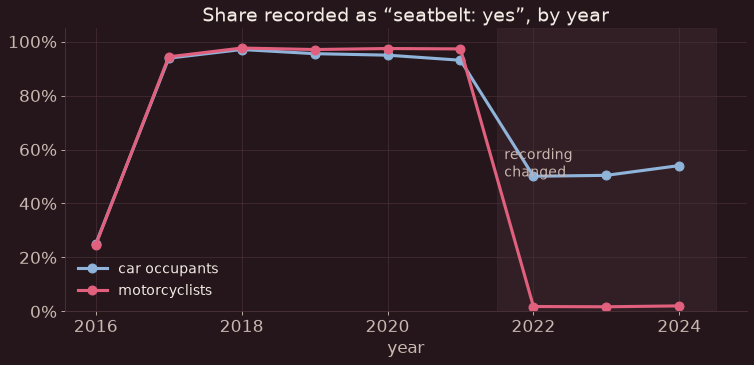

group,car occupants,motorcyclists
year,,
2016,0.250,0.247
2017,0.939,0.943
2018,0.971,0.976
2019,0.955,0.971
2020,0.950,0.974
2021,0.931,0.973
2022,0.501,0.018
2023,0.504,0.017
2024,0.541,0.021


In [8]:
# A column that changed its meaning: share recorded as "belt on", by year and group
d = df[df["seatbelt"].isin(["SIM", "NÃO"])].assign(belt=lambda x: (x["seatbelt"] == "SIM").astype(int))
d["group"] = np.select([d["vehicle"].isin(["car", "pickup/van"]) & d["role"].isin(["driver", "passenger"]),
                        d["vehicle"].eq("motorcycle")], ["car occupants", "motorcyclists"], "other")
s = d[d["group"] != "other"].groupby(["year", "group"])["belt"].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4.6))
for g_, c in zip(s.columns, [BLUE, ORANGE]):
    ax.plot(s.index, s[g_], color=c, lw=2.8, marker="o", ms=8, label=g_)
ax.axvspan(2021.5, 2024.5, color=GRID, alpha=.35)
ax.text(2021.6, .5, "recording\nchanged", color=INK2, fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 1.05)
ax.set(title="Share recorded as “seatbelt: yes”, by year", xlabel="year")
ax.legend(frameon=False, loc="lower left")
keep(fig, "eda_seatbelt_drift")
s.round(3)

## 3. Cleaning

* Unknown outcome → dropped; age 0 with no birth date, age > 100 → NaN; blank vehicle → "none" (pedestrian);
  vehicle types → 8 groups; time → hour, weekday, month; speed limit 0 → NaN (95% unknown).
* Missing values: median + indicator for the logistic regression, NaN for the trees.
* **The 2023 vehicle file spells its ID column `N§_boletim`** (an encoding slip in the source). Without handling it,
  2023 vehicles silently fail to join. I found this on the test set: see section 9.
* **Leaks:** `INDICADOR_FATALIDADE` (= "was there a death") and the accident-type *name* ("… COM / SEM VITIMA FATAL")
  → dropped / merged. **Paperwork leak:** pavement and weather are recorded mostly for serious crashes (0.80% vs 0.16%
  deaths, in 9 of 9 years) → dropped. `sexo = "not recorded"` (2% of people, 5% injured) is kept as its own category
  and flagged.
* **Encoding:** one-hot for the 10 low-cardinality columns; the 1 km location cell (348 values) gets a cross-fitted,
  smoothed target mean (`smooth=100`), fitted inside each fold.

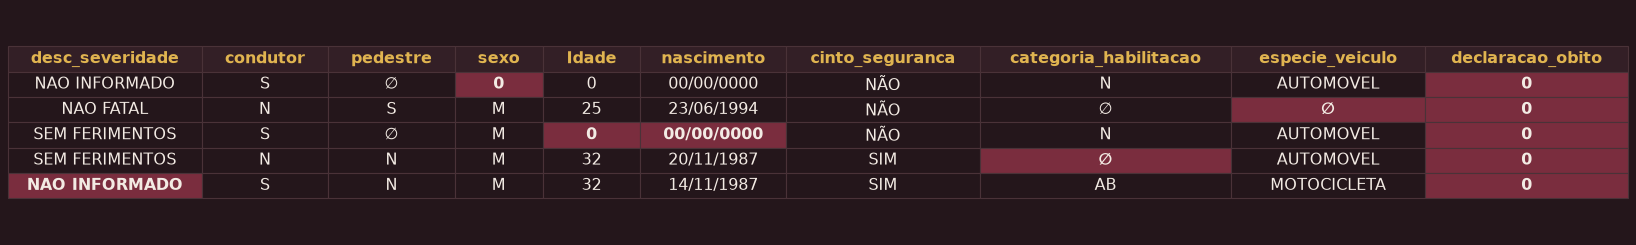

In [9]:
# Raw rows as they come, with the problems highlighted
raw = env[(env["year"] == 2020)].head(400)
show = pd.concat([raw[raw["sexo"] == "0"].head(1), raw[raw["especie_veiculo"] == ""].head(1),
                  raw[(raw["Idade"] == "0") & (raw["nascimento"] == "00/00/0000")].head(1),
                  raw[raw["categoria_habilitacao"] == ""].head(1), raw[raw["cod_severidade"] == "0"].head(1)])
cols = ["desc_severidade", "condutor", "pedestre", "sexo", "Idade", "nascimento", "cinto_seguranca",
        "categoria_habilitacao", "especie_veiculo", "declaracao_obito"]
t = show[cols].fillna("").replace({"": "∅"})
hl = {(0, 3), (1, 8), (2, 4), (2, 5), (3, 7), (4, 0)} | {(i, 9) for i in range(len(t))}
table_png(t, "tbl_raw", hl_cells=hl, fs=14)

pedestrians by raw accident type:
                                            size   mean
accident_type_raw                                     
ABALROAMENTO COM VITIMA                     205  0.015
ATROPELAMENTO DE PESSOA COM VITIMA FATAL    372  0.941
ATROPELAMENTO DE PESSOA SEM VITIMA FATAL  12422  0.000
CHOQUE MECANICO COM VITIMA                  306  0.023
OUTROS COM VITIMA                           244  0.025

INDICADOR_FATALIDADE vs person death:
 y                          0     1
INDICADOR_FATALIDADE              
NÃO                   228688    19
SIM                     1178  1093


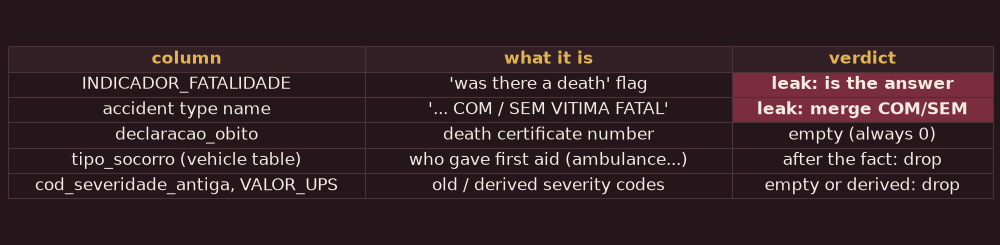

In [10]:
# The leakage hunt: columns that know the answer
leak = pd.DataFrame({
    "column": ["INDICADOR_FATALIDADE", "accident type name", "declaracao_obito", "tipo_socorro (vehicle table)",
               "cod_severidade_antiga, VALOR_UPS"],
    "what it is": ["'was there a death' flag", "'... COM / SEM VITIMA FATAL'", "death certificate number",
                   "who gave first aid (ambulance...)", "old / derived severity codes"],
    "verdict": ["leak: is the answer", "leak: merge COM/SEM", "empty (always 0)", "after the fact: drop",
                "empty or derived: drop"],
})
ped = df[df["role"] == "pedestrian"].groupby("accident_type_raw")["y"].agg(["size", "mean"])
print("pedestrians by raw accident type:\n", ped[ped["size"] > 100].round(3))
print("\nINDICADOR_FATALIDADE vs person death:\n", pd.crosstab(df["INDICADOR_FATALIDADE"], df["y"]))
table_png(leak, "tbl_leaks", hl_cells={(0, 2), (1, 2)}, fs=15)

In [11]:
NUM = ["age", "hour", "speed_limit", "n_people", "n_vehicles"]
CAT = ["role", "vehicle", "sex", "seatbelt", "drunk", "licence", "accident_type", "region", "weekday", "month"]
HIGH = ["grid_cell"]          # many values: target encoding, fitted inside each training fold
LEAKY = ["INDICADOR_FATALIDADE", "accident_type_raw"]
RECORDING = ["weather", "pavement"]   # filled in mostly for serious crashes: they measure the paperwork (see below)
print(len(NUM), "numeric,", len(CAT), "categorical,", len(HIGH), "high-cardinality column;",
      df["grid_cell"].nunique(), "grid cells")
df[NUM].isna().mean().round(3).to_frame("missing share")

5 numeric, 10 categorical, 1 high-cardinality column; 352 grid cells


,missing share
age,0.037
hour,0.000
speed_limit,0.952
n_people,0.000
n_vehicles,0.000


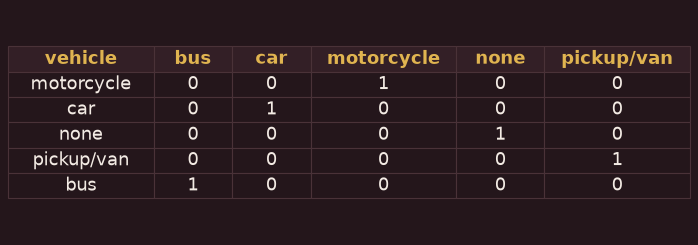

,vehicle,bus,car,motorcycle,none,pickup/van
0,motorcycle,0,0,1,0,0
1,car,0,1,0,0,0
2,none,0,0,0,1,0
3,pickup/van,0,0,0,0,1
4,bus,1,0,0,0,0


In [12]:
# One-hot: every value gets its own 0/1 column (real rows; "none" = no vehicle, i.e. a pedestrian, gets a column too)
ex = df[df["year"] == 2018].groupby("vehicle").head(1).head(5)[["vehicle"]].reset_index(drop=True)
oh = pd.get_dummies(ex["vehicle"], prefix="", prefix_sep="").astype(int)
table_png(pd.concat([ex, oh], axis=1), "tbl_onehot")
pd.concat([ex, oh], axis=1)

cells: 348 | with < 30 people: 38 | share of people in those: 0.002


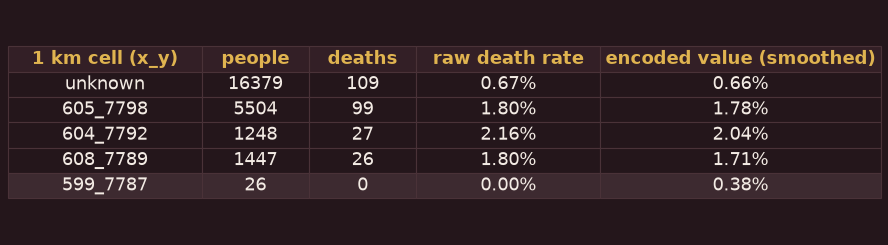

,grid_cell,people,deaths,rate,encoded
0,unknown,16379,109,0.67%,0.66%
1,605_7798,5504,99,1.80%,1.78%
2,604_7792,1248,27,2.16%,2.04%
3,608_7789,1447,26,1.80%,1.71%
4,599_7787,26,0,0.00%,0.38%


In [13]:
# Target encoding: each grid cell -> its death rate, computed on the TRAINING years only (2016–2022)
tr_cells = df[df["year"] <= 2022].groupby("grid_cell")["y"].agg(people="size", deaths="sum", rate="mean")
print("cells:", len(tr_cells), "| with < 30 people:", (tr_cells["people"] < 30).sum(),
      "| share of people in those:", round(tr_cells.loc[tr_cells["people"] < 30, "people"].sum() / tr_cells["people"].sum(), 3))
shown = pd.concat([tr_cells.sort_values("people", ascending=False).head(2), tr_cells[tr_cells["people"].between(300, 2000)].sort_values("rate", ascending=False).head(2),
                   tr_cells[tr_cells["people"] < 30].head(1)])
# what the model uses: (deaths + 100 × overall rate) / (people + 100), so small cells move toward the overall rate
te = TargetEncoder(target_type="binary", smooth=100).fit(df.loc[df["year"] <= 2022, ["grid_cell"]], df.loc[df["year"] <= 2022, "y"])
enc = dict(zip(te.categories_[0], te.encodings_[0]))
shown = shown.assign(encoded=[f"{enc[c]:.2%}" for c in shown.index], rate=shown["rate"].map(lambda r: f"{r:.2%}")).reset_index()
table_png(shown.rename(columns={"grid_cell": "1 km cell (x_y)", "rate": "raw death rate", "encoded": "encoded value (smoothed)"}),
          "tbl_target_enc", hl_rows={len(shown) - 1})
shown

## 4. Split first

**Train 2016–2022, test 2023–2024** (locked). CV: expanding window, validating on 2019, 2020, 2021, 2022, each time
training only on the years before. **No stratification:** the split is a date rule, not a random draw, so there is
nothing to stratify; the death rate is still similar on both sides (0.479% train, 0.489% test). **Seed:** none is
needed for the split itself; every model and the target encoder use SEED = 42. A random split would leak the future, and would split the people of one accident
between train and test. ~110 deaths per validation year: every CV number below has a large spread.

In [14]:
train = df[df["year"] <= 2022].reset_index(drop=True)
test = df[df["year"] >= 2023].reset_index(drop=True)          # LOCKED until section 9
y_tr = train["y"]
FOLDS = [(np.where(train["year"] < v)[0], np.where(train["year"] == v)[0]) for v in [2019, 2020, 2021, 2022]]
pd.DataFrame([{"validation year": v, "train years": f"2016–{v - 1}", "train rows": len(tr), "val rows": len(va),
               "val deaths": int(y_tr.iloc[va].sum())} for (tr, va), v in zip(FOLDS, [2019, 2020, 2021, 2022])])

,validation year,train years,train rows,val rows,val deaths
0,2019,2016–2018,75179,27779,105
1,2020,2016–2019,102958,21995,113
2,2021,2016–2020,124953,23290,113
3,2022,2016–2021,148243,25306,131


train 2016–2022: 173,549 people, 831 deaths (0.479%)
test 2023–2024:  57,429 people, 281 deaths (0.489%)


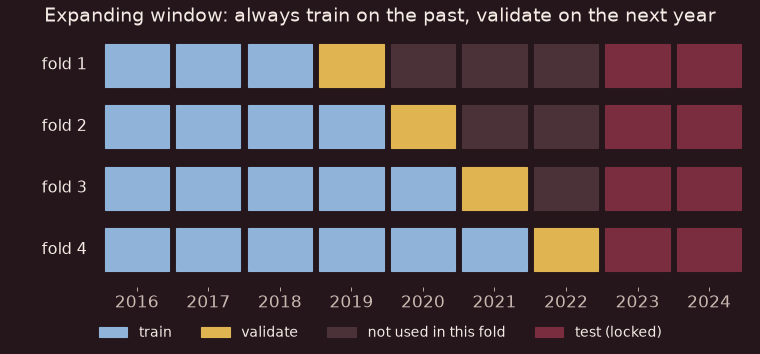

In [15]:
print(f"train 2016–2022: {len(train):,} people, {train['y'].sum()} deaths ({train['y'].mean():.3%})")
print(f"test 2023–2024:  {len(test):,} people, {test['y'].sum()} deaths ({test['y'].mean():.3%})")

# expanding-window CV diagram
fig, ax = plt.subplots(figsize=(12, 4.2))
yrs = list(range(2016, 2025))
for k, v in enumerate([2019, 2020, 2021, 2022]):
    for yr in yrs:
        c = BLUE if yr < v else GOLD if yr == v else (HL_CELL if yr >= 2023 else GRID)
        ax.add_patch(plt.Rectangle((yr - .45, 3 - k - .35), .9, .7, color=c))
    ax.text(2015.3, 3 - k, f"fold {k + 1}", ha="right", va="center", fontsize=14)
ax.set_xlim(2014.2, 2024.6)
ax.set_ylim(-.6, 3.6)
ax.set_xticks(yrs)
ax.set_yticks([])
ax.grid(visible=False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in [BLUE, GOLD, GRID, HL_CELL]],
          labels=["train", "validate", "not used in this fold", "test (locked)"], frameon=False, ncol=4,
          loc="upper center", bbox_to_anchor=(.5, -.1))
ax.set_title("Expanding window: always train on the past, validate on the next year")
keep(fig, "cv_time")

## 5. Baseline models

Dummy → logistic regression → tree (unlimited, depth 6) → random forest → XGBoost, the same features and the same four
folds. Main metric chosen in advance: **PR-AUC**.

In [16]:
def target_enc():
    # cross-fitted inside fit(): a row's own outcome never enters its own encoding
    # smooth=100: each cell is blended with the overall rate as if it had 100 extra people at that rate
    return TargetEncoder(target_type="binary", smooth=100, cv=KFold(5, shuffle=True, random_state=SEED))


def lin_prep(num, cat, high=HIGH):
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat),
        ("te", make_pipeline(target_enc(), StandardScaler()), high)])


def tree_prep(num, cat, high=HIGH):
    return ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
        ("te", target_enc(), high)])


XGB_BASE = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                tree_method="hist", n_jobs=-1, random_state=SEED)


def ladder(num, cat):
    T = lambda m: make_pipeline(tree_prep(num, cat), m)
    return {
        "dummy": T(DummyClassifier(strategy="prior")),
        "logistic regression": make_pipeline(lin_prep(num, cat), LogisticRegression(max_iter=5000)),
        "tree (no limit)": T(DecisionTreeClassifier(random_state=SEED)),
        "tree (depth 6)": T(DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEED)),
        "random forest": T(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
        "xgboost": T(XGBClassifier(**XGB_BASE)),
    }


def cv_eval(model, X, y, folds=FOLDS):
    oof = np.full(len(X), np.nan)
    pr, roc = [], []
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        pr.append(average_precision_score(y.iloc[va], p))
        roc.append(roc_auc_score(y.iloc[va], p))
    return np.array(pr), np.array(roc), oof


res, ROC, OOF = {}, {}, {}
for name, model in ladder(NUM, CAT).items():
    t0 = time.time()
    res[name], ROC[name], OOF[name] = cv_eval(model, train, y_tr)
    print(f"{name:20s} PR-AUC {res[name].mean():.4f} ± {res[name].std():.4f} | ROC-AUC {ROC[name].mean():.3f} | {time.time() - t0:4.0f} s")

dummy                PR-AUC 0.0047 ± 0.0006 | ROC-AUC 0.500 |    3 s


logistic regression  PR-AUC 0.0514 ± 0.0216 | ROC-AUC 0.829 |    9 s


tree (no limit)      PR-AUC 0.0066 ± 0.0010 | ROC-AUC 0.524 |    8 s


tree (depth 6)       PR-AUC 0.0403 ± 0.0086 | ROC-AUC 0.798 |    5 s


random forest        PR-AUC 0.0658 ± 0.0200 | ROC-AUC 0.859 |   83 s


xgboost              PR-AUC 0.0741 ± 0.0138 | ROC-AUC 0.871 |   15 s


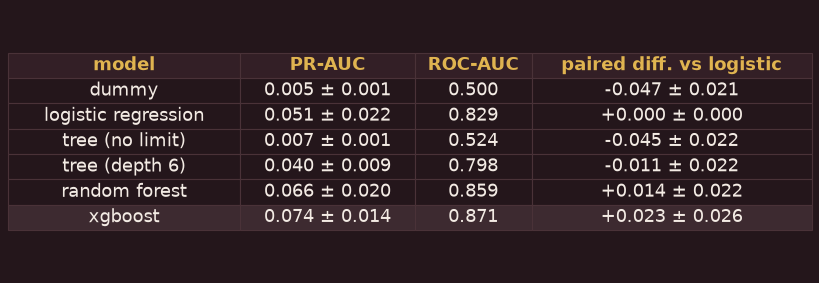

,model,PR-AUC,ROC-AUC,paired diff. vs logistic
0,dummy,0.005 ± 0.001,0.500,-0.047 ± 0.021
1,logistic regression,0.051 ± 0.022,0.829,+0.000 ± 0.000
2,tree (no limit),0.007 ± 0.001,0.524,-0.045 ± 0.022
3,tree (depth 6),0.040 ± 0.009,0.798,-0.011 ± 0.022
4,random forest,0.066 ± 0.020,0.859,+0.014 ± 0.022
5,xgboost,0.074 ± 0.014,0.871,+0.023 ± 0.026


In [17]:
b = res["logistic regression"]
ladder_tab = pd.DataFrame({
    "model": list(res),
    "PR-AUC": [f"{v.mean():.3f} ± {v.std():.3f}" for v in res.values()],
    "ROC-AUC": [f"{ROC[k].mean():.3f}" for k in res],
    "paired diff. vs logistic": [f"{(v - b).mean():+.3f} ± {(v - b).std():.3f}" for v in res.values()],
})
best_row = int(np.argmax([v.mean() for v in res.values()]))
table_png(ladder_tab, "tbl_ladder", hl_rows={best_row})
ladder_tab

In [18]:
# The leakage demo: the same XGBoost, but with the two leaky columns left in
leaky_pr, _, _ = cv_eval(make_pipeline(tree_prep(NUM, CAT + LEAKY), XGBClassifier(**XGB_BASE)), train, y_tr)
print(f"XGBoost WITH the leaky columns: PR-AUC {leaky_pr.mean():.3f} ± {leaky_pr.std():.3f}  (clean: {res['xgboost'].mean():.3f})")

XGBoost WITH the leaky columns: PR-AUC 0.877 ± 0.055  (clean: 0.074)


recorded  not recorded  recorded
year                            
2016            0.0017    0.0093
2017            0.0025    0.0074
2018            0.0017    0.0079
2019            0.0007    0.0068
2020            0.0017    0.0075
2021            0.0024    0.0074
2022            0.0021    0.0086
2023            0.0004    0.0073
2024            0.0013    0.0100


XGBoost WITH weather + pavement: PR-AUC 0.084 ± 0.021 | without: 0.074 ± 0.014


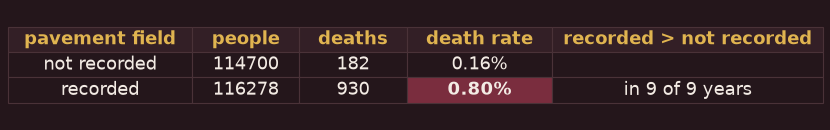

,pavement field,people,deaths,death rate,recorded > not recorded
0,not recorded,114700,182,0.16%,
1,recorded,116278,930,0.80%,in 9 of 9 years


In [19]:
# The quieter leak: weather and pavement are "not recorded" for half of the people, and that is not random
rec = df.assign(recorded=np.where(df["pavement"] != "NAO INFORMADO", "recorded", "not recorded"))
rt = rec.groupby(["recorded"])["y"].agg(people="size", deaths="sum", rate="mean")
by_year = rec.groupby(["year", "recorded"])["y"].mean().unstack()
print(by_year.round(4))
rec_pr, _, _ = cv_eval(make_pipeline(tree_prep(NUM, CAT + RECORDING), XGBClassifier(**XGB_BASE)), train, y_tr)
print(f"XGBoost WITH weather + pavement: PR-AUC {rec_pr.mean():.3f} ± {rec_pr.std():.3f} | without: {res['xgboost'].mean():.3f} ± {res['xgboost'].std():.3f}")
rt_show = rt.reset_index().assign(rate=lambda d: d["rate"].map(lambda v: f"{v:.2%}"),
                                  higher_in=["", f"in {(by_year['recorded'] > by_year['not recorded']).sum()} of 9 years"])
rt_show.columns = ["pavement field", "people", "deaths", "death rate", "recorded > not recorded"]
table_png(rt_show, "tbl_recording", hl_cells={(1, 3)})
rt_show

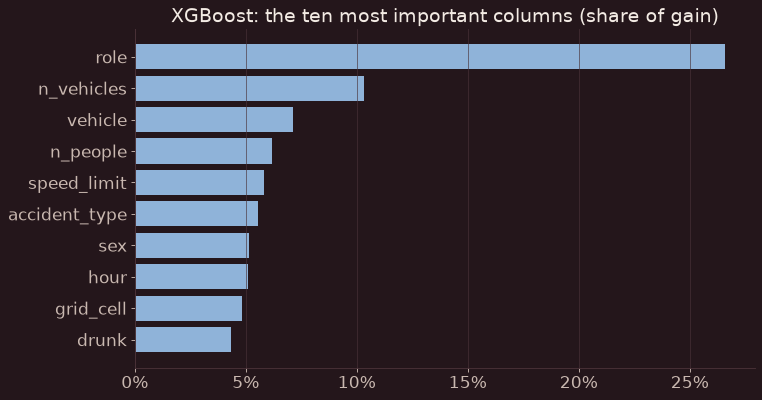

In [20]:
# What does XGBoost look at? (gain importance, fitted on 2016–2022)
xgb_full = clone(ladder(NUM, CAT)["xgboost"]).fit(train, y_tr)
imp = pd.Series(xgb_full[-1].get_booster().get_score(importance_type="gain"))
imp.index = [(NUM + CAT + HIGH)[int(i[1:])] for i in imp.index]
imp = (imp / imp.sum()).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(imp.index, imp.values, color=BLUE)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="XGBoost: the ten most important columns (share of gain)")
ax.grid(axis="y", visible=False)
keep(fig, "xgb_importance")

* Dummy 0.005 (the base rate), unlimited tree 0.007 (memorises), depth-6 tree 0.040, logistic **0.051 ± 0.022**,
  random forest 0.066, XGBoost **0.074 ± 0.014**.
* XGBoost − logistic, paired: **+0.023 ± 0.026**: smaller than its std, so by the course's rule **a tie on CV**.
* With the two leaky columns XGBoost reaches **0.877**: too good to be true. With pavement + weather: 0.084.

## 6. Metrics

The "nobody dies" model is **99.5% accurate** with recall 0, so raw accuracy is useless here. On the 2019–2022
out-of-fold predictions:

In [21]:
va_idx = np.concatenate([va for _, va in FOLDS])          # 2019–2022: every row has an out-of-fold prediction
yv = y_tr.iloc[va_idx].to_numpy()


def best_threshold(y, p):
    grid = np.unique(np.quantile(p, np.linspace(0.30, 0.995, 300)))
    ba = [balanced_accuracy_score(y, p >= t) for t in grid]
    return float(grid[int(np.argmax(ba))])


def top_capture(y, p, frac):
    # share of all deaths that fall into the riskiest `frac` of people, and the death rate there
    k = int(len(p) * frac)
    top = y[np.argsort(-p)[:k]]
    return top.sum() / y.sum(), top.mean()


def report(y, p, t):
    tn, fp, fn, tp = confusion_matrix(y, p >= t).ravel()
    cap5, rate5 = top_capture(y, p, 0.05)
    return {"threshold": round(t, 4), "accuracy": accuracy_score(y, p >= t), "balanced acc.": balanced_accuracy_score(y, p >= t),
            "recall": recall_score(y, p >= t), "precision": precision_score(y, p >= t, zero_division=0),
            "PR-AUC": average_precision_score(y, p), "deaths in riskiest 5%": cap5, "death rate in riskiest 5%": rate5,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


rows = {}
for name in ["dummy", "logistic regression", "xgboost"]:
    p = OOF[name][va_idx]
    rows[f"{name} @0.5"] = report(yv, p, 0.5)
    if name != "dummy":
        rows[f"{name} @best bal. acc."] = report(yv, p, best_threshold(yv, p))
metrics_tab = pd.DataFrame(rows).T
metrics_tab.round(4)

,threshold,accuracy,balanced acc.,recall,precision,PR-AUC,deaths in riskiest 5%,death rate in riskiest 5%,TP,FP,FN,TN
dummy @0.5,0.5000,0.9953,0.5000,0.0000,0.0000,0.0044,0.0346,0.0033,0.0,0.0,462.0,97908.0
logistic regression @0.5,0.5000,0.9946,0.5007,0.0022,0.0149,0.0365,0.3745,0.0352,1.0,66.0,461.0,97842.0
logistic regression @best bal. acc.,0.0060,0.7924,0.7525,0.7121,0.0160,0.0365,0.3745,0.0352,329.0,20285.0,133.0,77623.0
xgboost @0.5,0.5000,0.9953,0.5043,0.0087,0.8000,0.0685,0.4567,0.0429,4.0,1.0,458.0,97907.0
xgboost @best bal. acc.,0.0035,0.7656,0.7939,0.8225,0.0163,0.0685,0.4567,0.0429,380.0,22977.0,82.0,74931.0


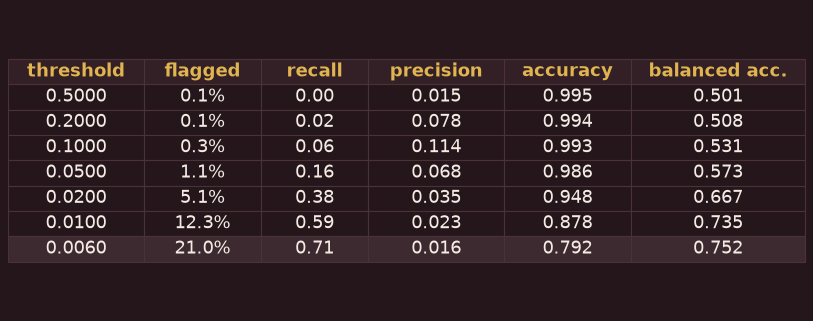

,threshold,flagged,recall,precision,accuracy,balanced acc.
0,0.5000,0.1%,0.00,0.015,0.995,0.501
1,0.2000,0.1%,0.02,0.078,0.994,0.508
2,0.1000,0.3%,0.06,0.114,0.993,0.531
3,0.0500,1.1%,0.16,0.068,0.986,0.573
4,0.0200,5.1%,0.38,0.035,0.948,0.667
5,0.0100,12.3%,0.59,0.023,0.878,0.735
6,0.0060,21.0%,0.71,0.016,0.792,0.752


In [22]:
# Moving the threshold (logistic regression, out-of-fold)
p_lr = OOF["logistic regression"][va_idx]
thr_rows = []
for t in [0.5, 0.2, 0.1, 0.05, 0.02, 0.01, best_threshold(yv, p_lr)]:
    thr_rows.append({"threshold": f"{t:.4f}", "flagged": f"{(p_lr >= t).mean():.1%}", "recall": f"{recall_score(yv, p_lr >= t):.2f}",
                     "precision": f"{precision_score(yv, p_lr >= t, zero_division=0):.3f}", "accuracy": f"{accuracy_score(yv, p_lr >= t):.3f}",
                     "balanced acc.": f"{balanced_accuracy_score(yv, p_lr >= t):.3f}"})
thr_tab = pd.DataFrame(thr_rows)
table_png(thr_tab, "tbl_threshold", hl_rows={len(thr_tab) - 1})
thr_tab

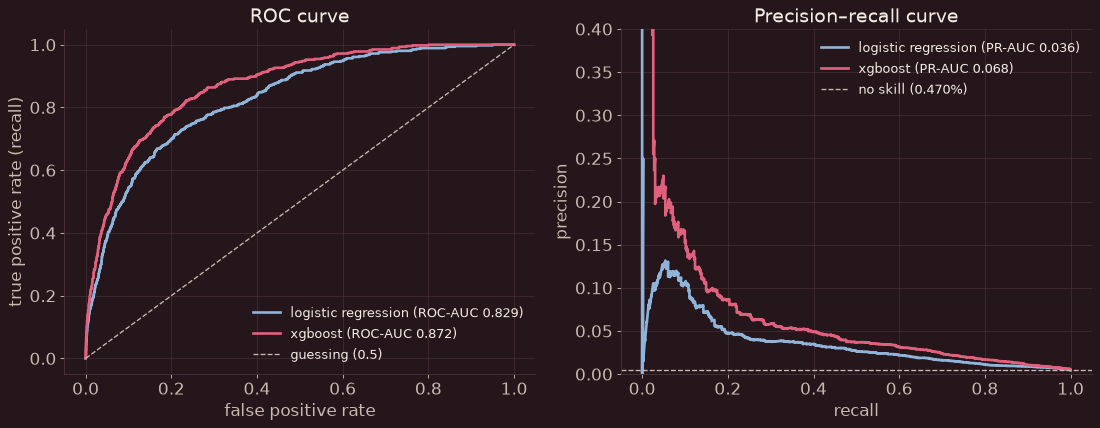

In [23]:
from sklearn.metrics import roc_curve
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6))
for name, color in [("logistic regression", BLUE), ("xgboost", ORANGE)]:
    p_ = OOF[name][va_idx]
    fpr, tpr, _ = roc_curve(yv, p_)
    a1.plot(fpr, tpr, color=color, lw=2.4, label=f"{name} (ROC-AUC {roc_auc_score(yv, p_):.3f})")
    prec, rec, _ = precision_recall_curve(yv, p_)
    a2.plot(rec, prec, color=color, lw=2.4, label=f"{name} (PR-AUC {average_precision_score(yv, p_):.3f})")
a1.plot([0, 1], [0, 1], color=INK2, ls="--", lw=1.2, label="guessing (0.5)")
a1.set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve")
a2.axhline(yv.mean(), color=INK2, ls="--", lw=1.2, label=f"no skill ({yv.mean():.3%})")
a2.set(xlabel="recall", ylabel="precision", ylim=(0, .4), title="Precision–recall curve")
for a in (a1, a2):
    a.legend(frameon=False, fontsize=12, loc="lower right" if a is a1 else "upper right")
plt.tight_layout()
keep(fig, "metrics_roc_pr")

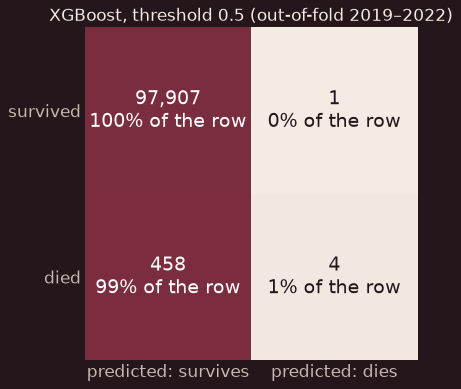

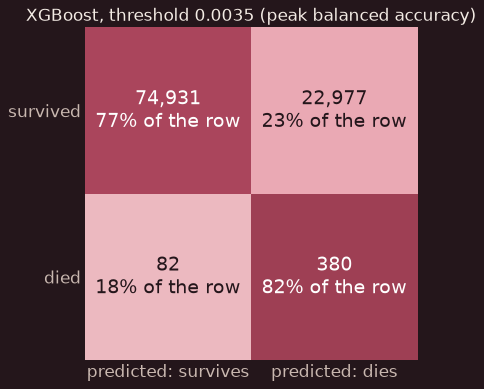

In [24]:
def cm_png(y, p, t, title, name):
    cm = confusion_matrix(y, p >= t)
    fig, ax = plt.subplots(figsize=(7.2, 5.4))
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            share = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]:,}\n{share:.0%} of the row", ha="center", va="center", fontsize=17,
                    color="white" if share > .5 else SURFACE)
    ax.set_xticks([0, 1], ["predicted: survives", "predicted: dies"])
    ax.set_yticks([0, 1], ["survived", "died"])
    ax.grid(visible=False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=15)
    keep(fig, name)


p = OOF["xgboost"][va_idx]
T_XGB = best_threshold(yv, p)
cm_png(yv, p, 0.5, "XGBoost, threshold 0.5 (out-of-fold 2019–2022)", "cm_xgb_05")
cm_png(yv, p, T_XGB, f"XGBoost, threshold {T_XGB:.4f} (peak balanced accuracy)", "cm_xgb_best")

* At 0.5, XGBoost finds 4 of 462 deaths (balanced accuracy 0.504). At its peak-balanced-accuracy threshold (0.0035):
  recall 0.82 (380 / 462), precision 0.016, 22,977 false alarms.
* ROC-AUC 0.83–0.87 looks excellent; PR-AUC 0.04–0.07 against a baseline of 0.0047 is the honest picture.
* Riskiest 5% by XGBoost: **46%** of the deaths (death rate 4.3%, 9× average); logistic: 37%.

## 7. Feedback loop

Errors studied on the out-of-fold predictions only. The most confidently missed deaths are drivers in crashes with a
**bus or truck**; the false alarms are pedestrians hit by motorcycles who survived. **Hypothesis:** the other vehicle
matters, and it is not in the person's row. Weight classes: pedestrian 0, bicycle 1, motorcycle 2, car 3, pickup/van 4,
bus/truck 5.

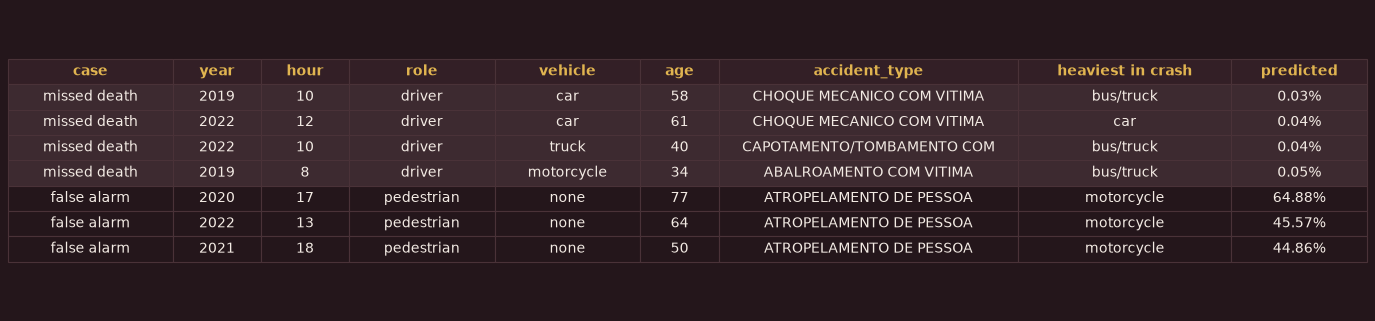

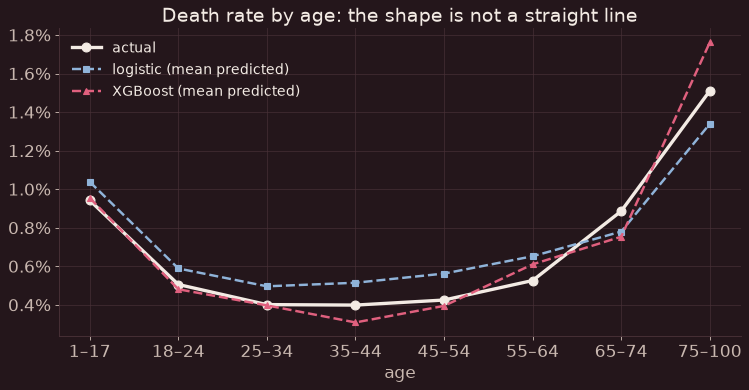

,people,actual,xgboost,logistic
age,,,,
"(0, 17]",2124,0.0094,0.0095,0.0104
"(17, 24]",17810,0.0051,0.0048,0.0059
"(24, 34]",26925,0.0040,0.0040,0.0050
"(34, 44]",22076,0.0040,0.0031,0.0051
"(44, 54]",13653,0.0042,0.0039,0.0056
"(54, 64]",7604,0.0053,0.0061,0.0065
"(64, 74]",3160,0.0089,0.0075,0.0078
"(74, 100]",1192,0.0151,0.0176,0.0134


In [25]:
# Who hit whom? The heaviest vehicle in the accident, from the vehicle table (no target used)
WEIGHT = {"none": 0, "bicycle": 1, "motorcycle": 2, "car": 3, "pickup/van": 4, "bus": 5, "truck": 5}
vv = veic.assign(w=veic["descricao_especie"].map(VEH).map(WEIGHT))
heavy = vv.groupby("num_boletim")["w"].max()
has_heavy = vv.groupby("num_boletim")["w"].apply(lambda s: int((s == 5).any()))


def add_partner(d):
    d = d.copy()
    d["own_weight"] = d["vehicle"].map(WEIGHT)
    d["heaviest_vehicle"] = d["num_boletim"].map(heavy)
    d["weight_gap"] = d["heaviest_vehicle"] - d["own_weight"]        # difference of two columns
    d["bus_or_truck_involved"] = d["num_boletim"].map(has_heavy)
    return d


train, test = add_partner(train), add_partner(test)

E = train.iloc[va_idx].assign(p=p, y=yv, missed=(yv == 1) & (p < T_XGB))

# Look at mistakes: the most confidently missed deaths and the most confident false alarms
cols = ["year", "hour", "role", "vehicle", "age", "accident_type", "heaviest_vehicle", "p"]
miss = E[E["y"] == 1].nsmallest(4, "p")[cols]
fa = E[E["y"] == 0].nlargest(3, "p")[cols]
mist = pd.concat([miss.assign(case="missed death"), fa.assign(case="false alarm")])
mist = mist.assign(p=mist["p"].map(lambda v: f"{v:.2%}"), age=mist["age"].map(lambda v: "?" if pd.isna(v) else int(v)),
                   accident_type=mist["accident_type"].str.slice(0, 26),
                   heaviest_vehicle=mist["heaviest_vehicle"].map({0: "-", 1: "bicycle", 2: "motorcycle", 3: "car", 4: "pickup/van", 5: "bus/truck"}).fillna("?"))
table_png(mist[["case"] + cols].rename(columns={"p": "predicted", "heaviest_vehicle": "heaviest in crash"}), "tbl_mistakes",
          hl_rows=set(range(len(miss))), fs=13)
mist

# Shape check: does the risk follow a straight line in age? (actual vs. predicted, out-of-fold)
bands = pd.cut(E["age"], [0, 17, 24, 34, 44, 54, 64, 74, 100])
shape = E.assign(lr=OOF["logistic regression"][va_idx]).groupby(bands, observed=True).agg(
    people=("y", "size"), actual=("y", "mean"), xgboost=("p", "mean"), logistic=("lr", "mean"))
fig, ax = plt.subplots(figsize=(11, 5))
xs = np.arange(len(shape))
ax.plot(xs, shape["actual"], color=INK, lw=3, marker="o", ms=8, label="actual")
ax.plot(xs, shape["logistic"], color=BLUE, lw=2.2, marker="s", ls="--", label="logistic (mean predicted)")
ax.plot(xs, shape["xgboost"], color=ORANGE, lw=2.2, marker="^", ls="--", label="XGBoost (mean predicted)")
ax.set_xticks(xs, [f"{int(i.left) + 1}–{int(i.right)}" for i in shape.index])
ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="age", title="Death rate by age: the shape is not a straight line")
ax.legend(frameon=False)
keep(fig, "loop_age_shape")
shape.round(4)

In [26]:
print(f"missed deaths at threshold {T_XGB:.4f}: {int(E['missed'].sum())} of {int(E['y'].sum())}")
g = (E.assign(gap=pd.cut(E["weight_gap"], [-9, 0, 1, 2, 3, 9], labels=["≤0", "1", "2", "3", "4–5"]))
       .groupby("gap", observed=True).agg(people=("y", "size"), deaths=("y", "sum"), actual=("y", "mean"),
                                         predicted=("p", "mean"), missed=("missed", "sum")))
g["recall"] = 1 - g["missed"] / g["deaths"]
g.round(4)

missed deaths at threshold 0.0035: 82 of 462


,people,deaths,actual,predicted,missed,recall
gap,,,,,,
≤0,58411,160,0.0027,0.0028,33,0.7938
1,27074,55,0.0020,0.0036,19,0.6545
2,6114,46,0.0075,0.0104,7,0.8478
3,5193,135,0.0260,0.0165,18,0.8667
4–5,1058,57,0.0539,0.0210,5,0.9123


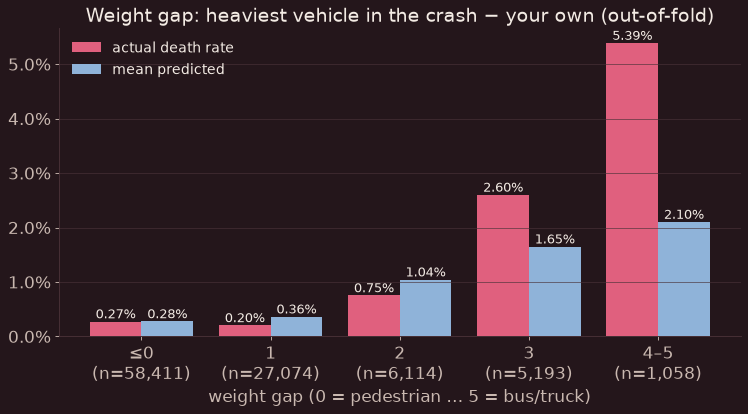

In [27]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(g))
ax.bar(x - .2, g["actual"], .4, color=ORANGE, label="actual death rate")
ax.bar(x + .2, g["predicted"], .4, color=BLUE, label="mean predicted")
for i, (a_, p_, n) in enumerate(zip(g["actual"], g["predicted"], g["people"])):
    ax.text(i - .2, a_, f"{a_:.2%}", ha="center", va="bottom", fontsize=12)
    ax.text(i + .2, p_, f"{p_:.2%}", ha="center", va="bottom", fontsize=12)
ax.set_xticks(x, [f"{k}\n(n={n:,})" for k, n in zip(g.index.astype(str), g["people"])])
ax.yaxis.set_major_formatter(pct)
ax.set(title="Weight gap: heaviest vehicle in the crash − your own (out-of-fold)", xlabel="weight gap (0 = pedestrian … 5 = bus/truck)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
keep(fig, "loop_weight_gap")

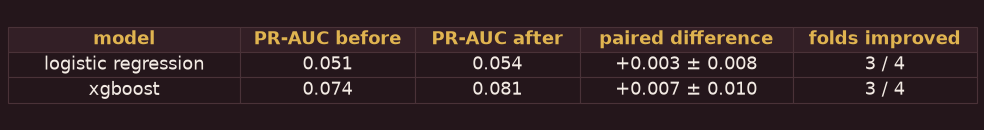

,model,PR-AUC before,PR-AUC after,paired difference,folds improved
0,logistic regression,0.051,0.054,+0.003 ± 0.008,3 / 4
1,xgboost,0.074,0.081,+0.007 ± 0.010,3 / 4


In [28]:
FE = ["heaviest_vehicle", "weight_gap", "bus_or_truck_involved"]
fe_rows = []
for mname in ["logistic regression", "xgboost"]:
    pr, roc, OOF[mname + " + FE"] = cv_eval(ladder(NUM + FE, CAT)[mname], train, y_tr)
    d = pr - res[mname]
    fe_rows.append({"model": mname, "PR-AUC before": f"{res[mname].mean():.3f}", "PR-AUC after": f"{pr.mean():.3f}",
                    "paired difference": f"{d.mean():+.3f} ± {d.std():.3f}", "folds improved": f"{(d > 0).sum()} / 4"})
fe_tab = pd.DataFrame(fe_rows)
table_png(fe_tab, "tbl_fe")
fe_tab

* The error is real: at a weight gap of 4–5 the death rate is **5.4%**, the model predicts 2.1% (a staircase:
  0.2% → 0.8% → 2.6% → 5.4%). Age is a U, and both models already follow it; I found no inverted U as in class.
* **The new features do not provably help:** XGBoost +0.007 ± 0.010, logistic +0.003 ± 0.008, better in 3 of 4 folds
  each, all within the noise. Only 1,058 people (57 deaths) in 2019–2022 have a gap of 4–5. I keep the features in the
  final candidates (they did not hurt) and report the gain as not proven.

## 8. Tuning

Random search (10 XGBoost candidates) on the 2019–2020 folds; the winner is checked on 2021–2022, unseen by the search.

best: {'n_estimators': 200, 'learning_rate': 0.02, 'max_depth': 4, 'min_child_weight': 1, 'subsample': 1, 'colsample_bytree': 1} | search score 0.0923
2021–2022 (unseen by the search): logistic 0.046 | XGBoost default 0.083 | tuned 0.088
tuned − default: +0.006 ± 0.000


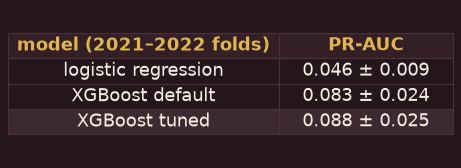

,subsample,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,PR-AUC (search)
4,1.0,200,1,4,0.02,1.0,0.0923
2,1.0,300,1,6,0.02,0.8,0.0893
5,1.0,300,20,3,0.02,0.8,0.0863
7,0.7,200,1,3,0.05,0.5,0.0852
9,0.7,200,20,3,0.05,0.8,0.0845
6,0.7,200,20,6,0.02,0.5,0.0841
3,0.8,300,1,4,0.05,0.8,0.0800
8,0.8,600,20,4,0.05,0.5,0.0760
1,0.8,300,5,6,0.05,0.5,0.0751
0,0.7,200,5,6,0.10,0.8,0.0719


In [29]:
FEAT = NUM + FE
SPACE = {"n_estimators": [200, 300, 600], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6],
         "min_child_weight": [1, 5, 20], "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0]}
SEARCH, CHECK = FOLDS[:2], FOLDS[2:]          # search on 2019–2020, check on 2021–2022


def xgb(**kw):
    return make_pipeline(tree_prep(FEAT, CAT), XGBClassifier(**{**XGB_BASE, **kw}))


cands = []
for params in ParameterSampler(SPACE, n_iter=10, random_state=SEED):
    pr, _, _ = cv_eval(xgb(**params), train, y_tr, SEARCH)
    cands.append({**params, "PR-AUC (search)": pr.mean()})
cands = pd.DataFrame(cands).sort_values("PR-AUC (search)", ascending=False)
best_params = {k: (int(v) if float(v).is_integer() else float(v)) for k, v in cands.iloc[0][list(SPACE)].items()}
base_pr, _, _ = cv_eval(xgb(), train, y_tr, CHECK)
tuned_pr, _, _ = cv_eval(xgb(**best_params), train, y_tr, CHECK)
lr_pr, _, _ = cv_eval(ladder(FEAT, CAT)["logistic regression"], train, y_tr, CHECK)
print("best:", best_params, "| search score", round(cands.iloc[0]["PR-AUC (search)"], 4))
print(f"2021–2022 (unseen by the search): logistic {lr_pr.mean():.3f} | XGBoost default {base_pr.mean():.3f} | tuned {tuned_pr.mean():.3f}")
print(f"tuned − default: {(tuned_pr - base_pr).mean():+.3f} ± {(tuned_pr - base_pr).std():.3f}")
tune_tab = pd.DataFrame({"model (2021–2022 folds)": ["logistic regression", "XGBoost default", "XGBoost tuned"],
                         "PR-AUC": [f"{v.mean():.3f} ± {v.std():.3f}" for v in [lr_pr, base_pr, tuned_pr]]})
table_png(tune_tab, "tbl_tuning", hl_rows={int(np.argmax([lr_pr.mean(), base_pr.mean(), tuned_pr.mean()]))})
cands.round(4)

Tuned 0.088 vs default 0.083 on the unseen folds: **+0.006**, the same in both. A simpler model won (200 trees, learning
rate 0.02, depth 4). The search score (0.092) is optimistic, as the maximum of 10 tries always is.

## 9. The test set — once

**Rule fixed in advance:** the best of {logistic, XGBoost default, XGBoost tuned} on the 2021–2022 folds → tuned
XGBoost; threshold = peak balanced accuracy on the training out-of-fold predictions. Then 2023–2024, once. The bootstrap
resamples **accidents**, not people.

In [30]:
candidates = {"logistic": lr_pr.mean(), "XGBoost default": base_pr.mean(), "XGBoost tuned": tuned_pr.mean()}
chosen = max(candidates, key=candidates.get)
final = {"logistic": ladder(FEAT, CAT)["logistic regression"], "XGBoost default": xgb(), "XGBoost tuned": xgb(**best_params)}[chosen]
_, _, oof_final = cv_eval(final, train, y_tr)
T_FINAL = best_threshold(yv, oof_final[va_idx])
print("chosen:", chosen, "| threshold from OOF predictions:", round(T_FINAL, 4))

final.fit(train, y_tr)
baseline = ladder(NUM, CAT)["logistic regression"].fit(train, y_tr)
T_BASE = best_threshold(yv, OOF["logistic regression"][va_idx])
y_te = test["y"].to_numpy()
p_final, p_base = final.predict_proba(test)[:, 1], baseline.predict_proba(test)[:, 1]
final_tab = pd.DataFrame({f"{chosen} (final)": report(y_te, p_final, T_FINAL),
                          "logistic (baseline)": report(y_te, p_base, T_BASE)}).T
final_tab.round(4)

chosen: XGBoost tuned | threshold from OOF predictions: 0.0054


,threshold,accuracy,balanced acc.,recall,precision,PR-AUC,deaths in riskiest 5%,death rate in riskiest 5%,TP,FP,FN,TN
XGBoost tuned (final),0.0054,0.8607,0.8556,0.8505,0.0292,0.1348,0.669,0.0655,239.0,7959.0,42.0,49189.0
logistic (baseline),0.0060,0.7836,0.7656,0.7473,0.0167,0.0483,0.395,0.0387,210.0,12356.0,71.0,44792.0


In [31]:
# Does the threshold travel? Share of people flagged at T_FINAL, year by year
flag = pd.concat([
    pd.DataFrame({"year": train["year"].iloc[va_idx].to_numpy(), "p": oof_final[va_idx], "source": "out-of-fold (train)"}),
    pd.DataFrame({"year": test["year"].to_numpy(), "p": p_final, "source": "final model (test)"})])
flag.groupby(["source", "year"])["p"].agg(flagged=lambda s: (s >= T_FINAL).mean(), mean_pred="mean", median_pred="median").round(4)

flagged  mean_pred  median_pred
source              year                                 
final model (test)  2023   0.1409     0.0042       0.0014
                    2024   0.1447     0.0043       0.0014
out-of-fold (train) 2019   0.1468     0.0042       0.0014
                    2020   0.1468     0.0042       0.0014
                    2021   0.1455     0.0041       0.0015
                    2022   0.1480     0.0042       0.0015

In [32]:
def cluster_boot(y, preds, groups, n=1000, seed=SEED):
    # resample accidents, not people: everyone in one accident moves together
    codes, uniq = pd.factorize(groups)
    rng = np.random.default_rng(seed)
    out = np.empty((n, len(preds)))
    for b_ in range(n):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes]
        out[b_] = [average_precision_score(y, p_, sample_weight=w) for p_ in preds]
    return out


BOOT = cluster_boot(y_te, [p_final, p_base], test["num_boletim"])
ci = lambda v: (np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5))
for label, v in [("final", BOOT[:, 0]), ("baseline", BOOT[:, 1]), ("difference", BOOT[:, 0] - BOOT[:, 1])]:
    print(f"{label:10s} PR-AUC {ci(v)[0]:.3f} [{ci(v)[1]:.3f}; {ci(v)[2]:.3f}]")
print("no-skill line (death rate):", round(y_te.mean(), 4))

final      PR-AUC 0.137 [0.101; 0.174]
baseline   PR-AUC 0.051 [0.035; 0.071]
difference PR-AUC 0.086 [0.055; 0.119]
no-skill line (death rate): 0.0049


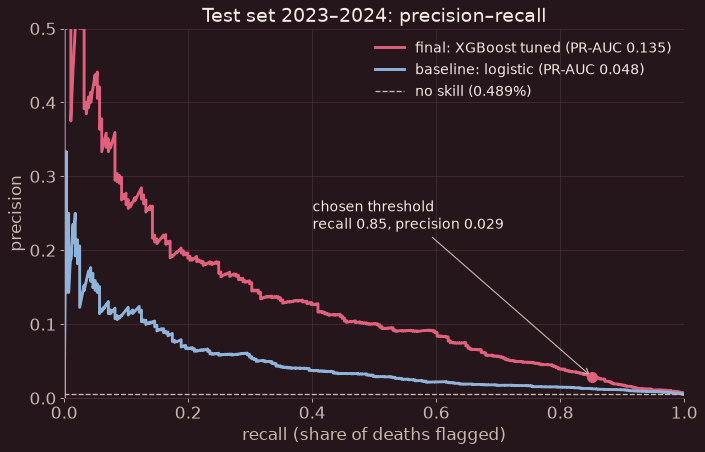

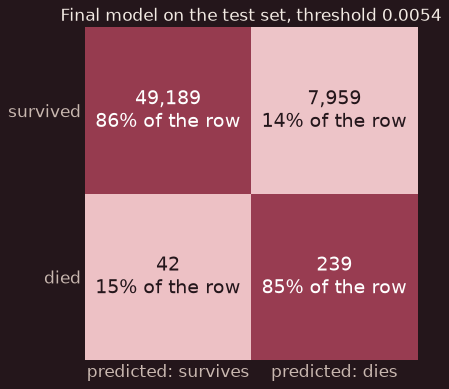

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
for p_, label, color in [(p_final, f"final: {chosen}", ORANGE), (p_base, "baseline: logistic", BLUE)]:
    prec, rec, _ = precision_recall_curve(y_te, p_)
    ax.plot(rec, prec, color=color, lw=2.6, label=f"{label} (PR-AUC {average_precision_score(y_te, p_):.3f})")
ax.axhline(y_te.mean(), color=INK2, ls="--", lw=1.2, label=f"no skill ({y_te.mean():.3%})")
r_f, p_f = recall_score(y_te, p_final >= T_FINAL), precision_score(y_te, p_final >= T_FINAL)
ax.scatter([r_f], [p_f], color=ORANGE, s=80, zorder=5)
ax.annotate(f"chosen threshold\nrecall {r_f:.2f}, precision {p_f:.3f}", (r_f, p_f), xytext=(r_f - .45, p_f + .2),
            arrowprops=dict(arrowstyle="->", color=INK2), fontsize=13)
ax.set(xlabel="recall (share of deaths flagged)", ylabel="precision", xlim=(0, 1), ylim=(0, .5),
       title="Test set 2023–2024: precision–recall")
ax.legend(frameon=False, loc="upper right")
keep(fig, "pr_test")
cm_png(y_te, p_final, T_FINAL, f"Final model on the test set, threshold {T_FINAL:.4f}", "cm_test")

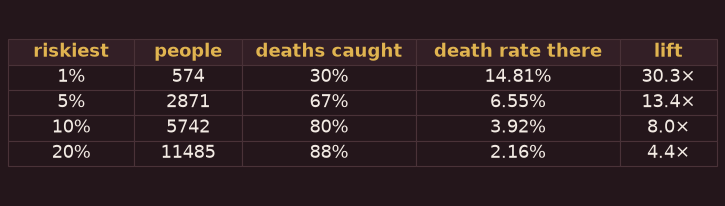

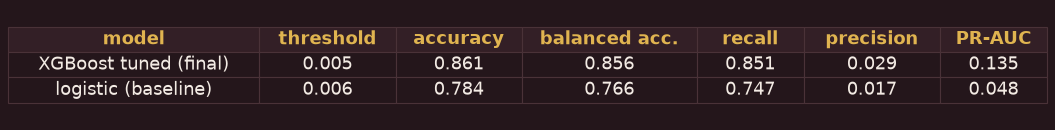

,riskiest,people,deaths caught,death rate there,lift
0,1%,574,30%,14.81%,30.3×
1,5%,2871,67%,6.55%,13.4×
2,10%,5742,80%,3.92%,8.0×
3,20%,11485,88%,2.16%,4.4×


In [34]:
cap = pd.DataFrame([{"riskiest": f"{f:.0%}", "people": int(len(y_te) * f),
                     "deaths caught": f"{top_capture(y_te, p_final, f)[0]:.0%}",
                     "death rate there": f"{top_capture(y_te, p_final, f)[1]:.2%}",
                     "lift": f"{top_capture(y_te, p_final, f)[1] / y_te.mean():.1f}×"} for f in [0.01, 0.05, 0.10, 0.20]])
table_png(cap, "tbl_capture")
fin = final_tab.loc[:, ["threshold", "accuracy", "balanced acc.", "recall", "precision", "PR-AUC"]].astype(float).round(3).reset_index(names="model")
table_png(fin, "tbl_final")
cap

* **281 deaths:** 239 flagged (recall 0.85), 42 missed, 7,959 false alarms (14% flagged); the logistic baseline flags
  210 with 12,356 false alarms.
* **PR-AUC 0.137 [0.101; 0.174]** vs 0.051 [0.035; 0.071]; paired difference **+0.086 [0.055; 0.119]**.
* Riskiest 1% → 30% of deaths; **5% → 67%**; 10% → 80%; 20% → 88%.
* The test score is higher than the CV estimate (0.088): wide interval, more training years. I trust the CV number more.
* **I looked at the test set twice.** The first run flagged 73% of people in 2023 (the threshold-by-year table above
  now checks for exactly this); the cause was the `N§_boletim` join bug. I fixed the data pipeline and re-ran; the model rule and
  the threshold rule did not change. Strictly, the test set is no longer untouched.

## 10. Limitations

1. **Few deaths:** ~110 per validation year make CV comparisons noisy; XGBoost vs logistic and the new features are
   within the fold-to-fold spread.
2. **The recording drifts and depends on the outcome:** the seatbelt field changed meaning in 2022, and report
   completeness follows severity. I removed the clearest cases; some recording signal surely remains.
3. **One city, police reports only:** later deaths in hospital may be recorded differently; nothing here is causal.

## Appendix — figures for `homework.md`

The same three charts as above (deaths by role and vehicle, the weight gap, the test confusion matrix), redrawn for
the written report in a navy-and-gold palette. The first chart groups the rows by role (pedestrians, drivers,
passengers) so it is visible that role and vehicle are two separate categorisations.

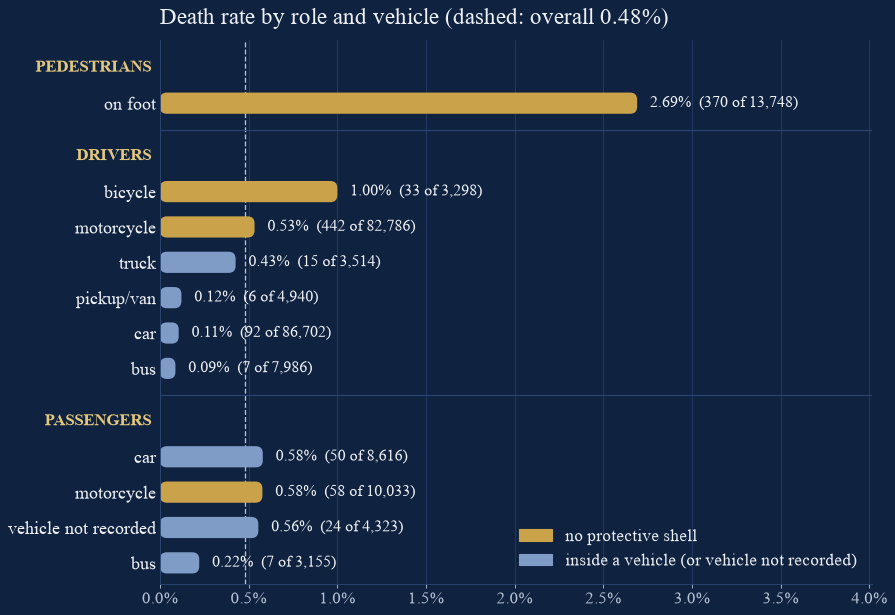

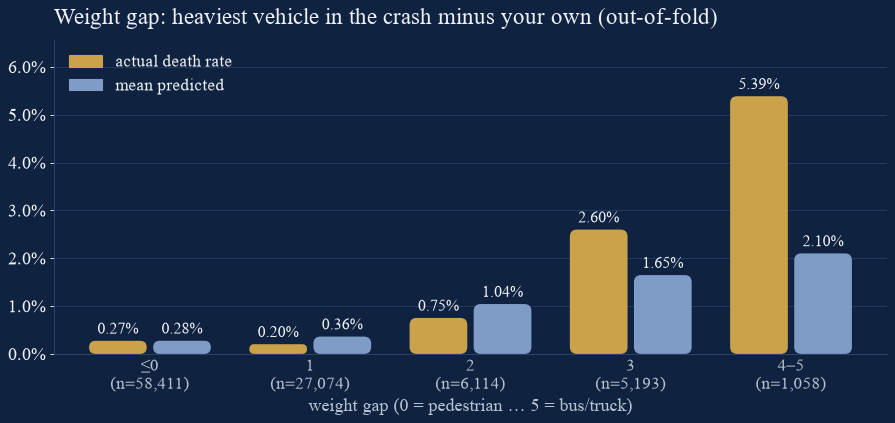

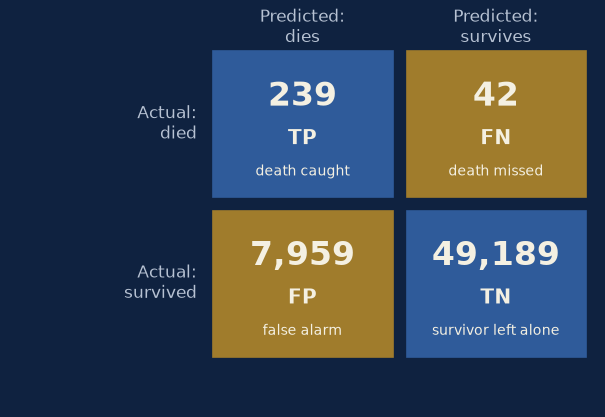

In [35]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# navy and gold, in the spirit of a university report
NAVY, NAVY2, LINE = "#0f2240", "#1b3358", "#2c4672"
TXT, TXT2 = "#eef1f6", "#b7c2d3"
GOLD, GOLD2, STEEL = "#c9a24a", "#e3c77d", "#7f9cc7"
NAVY_GOLD = LinearSegmentedColormap.from_list("navy_gold", [NAVY2, GOLD])
REPORT = {"figure.facecolor": NAVY, "axes.facecolor": NAVY, "savefig.facecolor": NAVY, "text.color": TXT,
          "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT, "axes.edgecolor": LINE, "grid.color": LINE,
          "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 17,
          "axes.titlesize": 21, "axes.labelsize": 16, "xtick.labelsize": 15, "ytick.labelsize": 16, "legend.fontsize": 15}


def save_md(fig, name):
    fig.savefig(ASSETS / f"{name}.png", dpi=170, bbox_inches="tight", facecolor=NAVY)
    plt.show()


def rounded_bar(ax, x, y, w, h, color, r_px=7):
    # a bar that ends exactly at its value, with corners rounded by r_px pixels (circular, whatever the axis scales)
    p0, p1 = ax.transData.transform((0, 0)), ax.transData.transform((1, 1))
    px_x, px_y = abs(p1[0] - p0[0]), abs(p1[1] - p0[1])
    r = min(r_px, abs(w) * px_x / 2, abs(h) * px_y / 2)
    rx, ry = r / px_x, r / px_y
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={rx}", mutation_aspect=ry / rx,
                                facecolor=color, edgecolor="none", zorder=2))


with plt.rc_context(REPORT):
    # 1. who dies, grouped by role (same numbers as eda_who)
    st = (df[df["role"] != "unknown"].groupby(["role", "vehicle"])["y"].agg(["size", "mean", "sum"]))
    st = st[st["size"] >= 2000]
    groups = [("PEDESTRIANS", "pedestrian"), ("DRIVERS", "driver"), ("PASSENGERS", "passenger")]
    rows, heads, y = [], [], 0.0
    for head, role in groups:
        if role == "pedestrian":
            # all pedestrians in one row (84 of them also have a vehicle filled in), as in eda_who
            part = df[df["role"] == "pedestrian"]["y"].agg(["size", "mean", "sum"]).to_frame("none").T
        else:
            part = st.loc[role].sort_values("mean", ascending=False)
        heads.append((head, y))
        y += 1
        for veh, r in part.iterrows():
            label = "on foot" if role == "pedestrian" else ("vehicle not recorded" if veh == "none" else veh)
            rows.append((y, label, r, veh))
            y += 1
        y += .5
    fig, ax = plt.subplots(figsize=(11.5, 8))
    ax.set_xlim(0, st["mean"].max() * 1.5)
    ax.set_ylim(y - .9, -.8)
    ax.set_yticks([r[0] for r in rows], [r[1] for r in rows])
    ax.xaxis.set_major_formatter(pct)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"Death rate by role and vehicle (dashed: overall {base:.2%})", loc="left", pad=14)
    fig.tight_layout()
    for head, hy in heads:
        ax.text(-0.012, hy, head, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=15,
                fontweight="bold", color=GOLD2)
        if hy > 0:
            ax.axhline(hy - .75, color=LINE, lw=1)
    for yy, label, r, veh in rows:
        soft = label == "on foot" or veh in ("motorcycle", "bicycle")
        rounded_bar(ax, 0, yy - .3, r["mean"], .6, GOLD if soft else STEEL)
        ax.text(r["mean"] + .0005, yy, f" {r['mean']:.2%}  ({int(r['sum'])} of {int(r['size']):,})", va="center",
                fontsize=14, color=TXT)
    ax.axvline(base, color=TXT2, ls="--", lw=1.2, zorder=1)
    ax.legend(handles=[Rectangle((0, 0), 1, 1, color=GOLD), Rectangle((0, 0), 1, 1, color=STEEL)],
              labels=["no protective shell", "inside a vehicle (or vehicle not recorded)"], frameon=False, loc="lower right")
    save_md(fig, "md_who")

    # 2. weight gap (same numbers as loop_weight_gap)
    gap = g.copy()
    fig, ax = plt.subplots(figsize=(11.5, 5.6))
    x = np.arange(len(gap))
    ax.set_xticks(x, [f"{k}\n(n={n:,})" for k, n in zip(gap.index.astype(str), gap["people"])])
    ax.set_ylim(0, gap["actual"].max() * 1.22)
    ax.set_xlim(-.6, len(gap) - .4)
    ax.yaxis.set_major_formatter(pct)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
    ax.set_xlabel("weight gap (0 = pedestrian … 5 = bus/truck)")
    ax.set_title("Weight gap: heaviest vehicle in the crash minus your own (out-of-fold)", loc="left", pad=14)
    ax.legend(handles=[Rectangle((0, 0), 1, 1, color=GOLD), Rectangle((0, 0), 1, 1, color=STEEL)],
              labels=["actual death rate", "mean predicted"], frameon=False, loc="upper left")
    fig.tight_layout()
    for i, (a_, p_) in enumerate(zip(gap["actual"], gap["predicted"])):
        rounded_bar(ax, i - .38, 0, .36, a_, GOLD)
        rounded_bar(ax, i + .02, 0, .36, p_, STEEL)
        ax.text(i - .2, a_ + .0008, f"{a_:.2%}", ha="center", va="bottom", fontsize=14)
        ax.text(i + .2, p_ + .0008, f"{p_:.2%}", ha="center", va="bottom", fontsize=14)
    save_md(fig, "md_weight_gap")

# 3. test confusion matrix: the lesson's 2x2 layout (cm_png in the lesson's demo.ipynb), in navy and gold
with plt.rc_context({"figure.facecolor": NAVY, "savefig.facecolor": NAVY}):
    tn, fp, fn, tp = confusion_matrix(y_te, p_final >= T_FINAL).ravel()
    fig, ax = plt.subplots(figsize=(9.5, 6.4))
    ax.axis("off")
    ax.set_xlim(-2.3, 4.4)
    ax.set_ylim(-.2, 4.5)
    RIGHT, WRONG, CREAM = "#2f5b9a", "#a07c2c", "#f4f0e2"
    cells = [(0, 0, tp, "TP", "death caught", RIGHT), (1, 0, fn, "FN", "death missed", WRONG),
             (0, 1, fp, "FP", "false alarm", WRONG), (1, 1, tn, "TN", "survivor left alone", RIGHT)]
    for cx, ry, val, tag, desc, col in cells:
        x0, y0 = cx * 2.2, 2.3 - ry * 1.9
        ax.add_patch(Rectangle((x0, y0), 2.1, 1.8, facecolor=col, edgecolor=NAVY, lw=3))
        ax.text(x0 + 1.05, y0 + 1.22, f"{val:,}", ha="center", va="center", fontsize=30, color=CREAM, fontweight="bold")
        ax.text(x0 + 1.05, y0 + .72, tag, ha="center", va="center", fontsize=18, color=CREAM, fontweight="bold")
        ax.text(x0 + 1.05, y0 + .33, desc, ha="center", va="center", fontsize=12.5, color=CREAM)
    ax.text(1.05, 4.35, "Predicted:\ndies", ha="center", va="center", fontsize=15, color=TXT2)
    ax.text(3.25, 4.35, "Predicted:\nsurvives", ha="center", va="center", fontsize=15, color=TXT2)
    ax.text(-.15, 3.2, "Actual:\ndied", ha="right", va="center", fontsize=15, color=TXT2)
    ax.text(-.15, 1.3, "Actual:\nsurvived", ha="right", va="center", fontsize=15, color=TXT2)
    save_md(fig, "md_test")